In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt

## Efficient Frontier

Efficicent Frontier - different weight combination for stocks in a portfolio

In [16]:
tickers = ["AAPL", "NKE", "PEP", "JPM","AMZN", "TSLA", "NFLX", "SLB"]

df_stocks_prices = yf.download(tickers, period="10y")[["Close"]]
df_stocks_prices.columns = ["AAPL", "NKE", "PEP", "JPM","AMZN", "TSLA", "NFLX", "SLB"]

df_stocks_returns = df_stocks_prices.pct_change(fill_method=None).dropna()

risk_free_rate = float(yf.download("^TNX", period="5d")["Close"].iloc[-1].iloc[0] / 100)


[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  1 of 1 completed


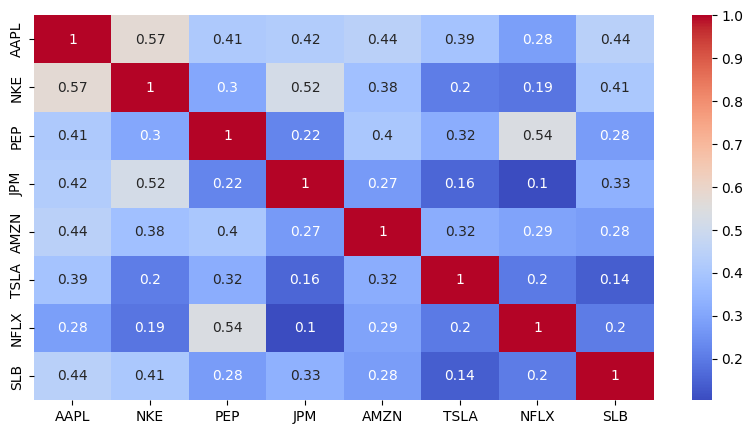

In [17]:
plt.figure(figsize=(10,5))
sns.heatmap(df_stocks_returns.corr(), annot=True, cmap="coolwarm")
plt.show()

In [18]:
def sortino_ratio(returns):
    annual_return = float(returns.mean() * 252)
    downside_std = float(returns[returns < 0].std() * np.sqrt(252))
    return (annual_return - risk_free_rate) / downside_std      # Return - Risk Free Rate / Negative Volatility



In [21]:
n_simulations = 100000
n_stocks = len(df_stocks_returns.columns)
results = []

for i in range(n_simulations):
    weights = np.random.random(n_stocks)
    weights = weights / weights.sum()

    portfolio_return    = float(df_stocks_returns.dot(weights).mean() * 252)
    portfolio_risk      = float(df_stocks_returns.dot(weights).std() * np.sqrt(252))
    portfolio_sortino   = float(sortino_ratio(df_stocks_returns.dot(weights)))

    results.append([portfolio_return, portfolio_risk, portfolio_sortino, weights])

results_df = pd.DataFrame(results, columns=["Return", "Risk", "Sortino", "Weights"])


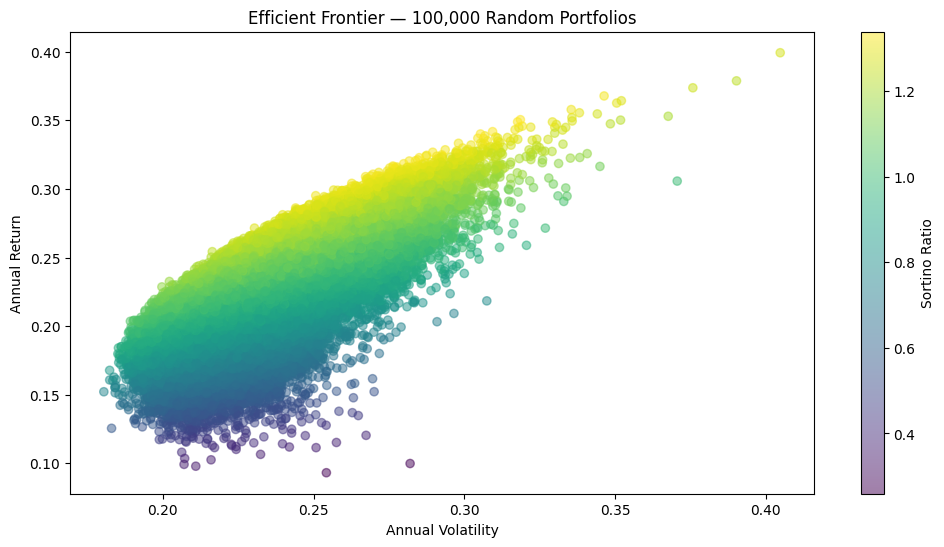

In [22]:
plt.figure(figsize=(12,6))
plt.scatter(results_df["Risk"], results_df["Return"],
            c=results_df["Sortino"], cmap="viridis", alpha=0.5)
plt.colorbar(label="Sortino Ratio")
plt.xlabel("Annual Volatility")
plt.ylabel("Annual Return")
plt.title("Efficient Frontier — 100,000 Random Portfolios")
plt.show()

each one scatter plot dot is refer to one simulated portfolio

In [24]:
best = results_df.loc[results_df["Sortino"].idxmax()]

print(f"Best Return   : {best["Return"]*100:.2f}%")
print(f"Best Risk     : {best["Risk"]*100:.2f}%")
print(f"Best Sortino  : {best["Sortino"]:.2f}")
print(f"\nOptimal Weights:")
for ticker, weight in zip(df_stocks_returns.columns, best["Weights"]):
    print(f"  {ticker} : {weight*100:.2f}%")

Best Return   : 34.01%
Best Risk     : 30.53%
Best Sortino  : 1.34

Optimal Weights:
  AAPL : 22.14%
  NKE : 1.97%
  PEP : 20.07%
  JPM : 15.79%
  AMZN : 2.65%
  TSLA : 2.10%
  NFLX : 0.79%
  SLB : 34.48%
